In [1]:
import sys
print(sys.executable)

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\python.exe


# Importacion de librerías, definición de raíz del proyecto y descarga de datos (setup)

In [2]:
from pathlib import Path
from dotenv import load_dotenv, find_dotenv
import requests
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegressionCV

Vamos a definir la raíz del proyecto y evitar rutas absolutas.

In [3]:
load_dotenv(find_dotenv())

PROJECT_ROOT = Path(find_dotenv()).parent.resolve()
print(f"PROJECT_ROOT set to: {PROJECT_ROOT}")

DATA_DIR = PROJECT_ROOT / 'data'

PROJECT_ROOT set to: C:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025


Comprobamos que el archivo existe y si no es así lo descargamos automáticamente.

In [4]:
DATA_URL = "https://data.mendeley.com/public-files/datasets/b24cb4nn8h/files/94aa2cf6-b4c1-4140-bfcc-d21040a14735/file_downloaded"
FILE_PATH = DATA_DIR / "synthea_30k.csv"

DATA_DIR.mkdir(parents = True ,exist_ok = True )

if not FILE_PATH.exists():
    print("Descargando dataset...")
    response = requests.get(DATA_URL)
    with open(FILE_PATH, 'wb') as f:
        f.write(response.content)
    print("Descarga completada.")
else:
    print("Dataset ya disponible localmente.")

Dataset ya disponible localmente.


# Creación de DataFrame y división de los datos

In [5]:
datos = pd.read_csv(FILE_PATH, low_memory=False)

In [6]:
datos.shape

(4221, 765)

In [7]:
datos.head()

,ptnum,label,scc,C-44465007,C-392091000,C-248595008,C-6246-3,C-197927001,C-234262008,C-389221,...,C-274804006,C-38822007,C-704-7,C-72514-3,C-6844-5,C-268556000,C-979492,C-122548005,C-141918,C-1359133
0,p15865,1,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
1,p27452,1,145,True,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,normal,NaN,NaN,NaN,NaN,NaN,NaN
2,p12382,1,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
3,p21814,1,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
4,p2902,1,127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,normal,NaN,NaN,NaN,NaN,NaN,NaN


Lo primero que nos llama la atención es la cantidad de datos faltantes y la enorme cantidad de variables. Para entender mejor cuales son estas variables recurrimos al repositorio GitHub del autor (https://github.com/lhs-open/synthetic-data/blob/main/lung-cancer-risk/synthea-lc-dataset-codes.csv) Donde en el archivo csv, da nombre a cada una de las variables. La codificación de estos nombres es la habitual en proyectos médicos y es el original standard code (SNOMED-CT, LOINC, etc.) precedido por 'C-' (Información extraida del readme del repositorio).

Gracias a esta información nos damos cuenta que es normal que falten tantos datos y es que se recoge información de enfermedades tan espécificas como un esguice de tobillo, la cual la mayoría de paciente no ha sufrido o puede que la haya sufrido pero no este recogido en los datos.

Sea como sea, es inviable trabajar con tantas variables con datos faltantes, haremos primero la selección de las 50 mejores variables para trabajar de una manera más eficiente. Pero antes, debemos de identificar la variable objetivo.

In [8]:
columnas_C = datos.filter(regex='^C-')
datos.drop(columnas_C,axis=1)

,ptnum,label,scc
0,p15865,1,150
1,p27452,1,145
2,p12382,1,133
3,p21814,1,132
4,p2902,1,127
...,...,...,...
4216,p9457,0,100
4217,p967,0,100
4218,p9736,0,100
4219,p9788,0,100


Extrayendo todas las columnas que empiezan por "C-". Nos quedamos únicamente con tres atributos, el identificador del paciente, una variable binaria y lo que parece ser otra de las variables explicativas `scc`. En este punto es fácil detectar que la variable que mide la presencia o no de cancér de pulmón es `label`, es decir, nuestra variable objetivo (target). 

In [9]:
datos=datos.rename(columns={'label': 'target'})
datos=datos.set_index("ptnum")

In [10]:
X= datos.drop("target",axis=1)
y=datos["target"]
X.head()

,scc,C-44465007,C-392091000,C-248595008,C-6246-3,C-197927001,C-234262008,C-389221,C-92691004,C-392021009,...,C-274804006,C-38822007,C-704-7,C-72514-3,C-6844-5,C-268556000,C-979492,C-122548005,C-141918,C-1359133
ptnum,,,,,,,,,,,,,,,,,,,,,
p15865,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
p27452,145,True,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,normal,NaN,NaN,NaN,NaN,NaN,NaN
p12382,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
p21814,132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,abnormal,NaN,NaN,NaN,NaN,NaN,NaN
p2902,127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,...,NaN,NaN,NaN,normal,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
from sklearn.model_selection import train_test_split

datos_train, datos_temp = train_test_split(datos, test_size=0.2, random_state=625, stratify=y)
y_temp = datos_temp["target"]
datos_val, datos_test = train_test_split(datos_temp, test_size=0.5, random_state=625, stratify=y_temp)

X_train = datos_train.drop("target", axis=1)
y_train = datos_train["target"]

X_val = datos_val.drop("target", axis=1)
y_val = datos_val["target"]

X_test = datos_test.drop("target", axis=1)
y_test = datos_test["target"]

# Creación de pipelines de preprocesado y modelado

In [12]:
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer


cat_pipeline = Pipeline([
    ("codif", OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ("imputer",SimpleImputer(strategy="constant", fill_value=0.0,keep_empty_features=True)),
])

preprocesamiento = ColumnTransformer([
    ("cat", cat_pipeline, make_column_selector(dtype_include="object")),
], remainder=(SimpleImputer(strategy="constant", fill_value=0.0)), verbose_feature_names_out=False)

seleccion = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("50mejores", SelectKBest(k=50)),
])

regresor = Pipeline([
    ("seleccion", seleccion),
    ("logistic_regression", LogisticRegressionCV(max_iter=1000, n_jobs=-1,scoring="recall", cv=5,random_state=625)),
])


In [13]:
modelo=regresor.fit(X_train, y_train)

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['C-26881-3' 'C-79733001' 'C-789980' 'C-309845' 'C-448417001'
 'C-171231001' 'C-48387007' 'C-979092' 'C-82078001' 'C-60951000119105'
 'C-200936003' 'C-104173009' 'C-698423002' 'C-448813005' 'C-14152002'
 'C-256277009' 'C-288328004' 'C-200243' 'C-1940648' 'C-408512008'
 'C-48333001' 'C-727711' 'C-281790008' 'C-113076002' 'C-782576004'
 'C-999998' 'C-2284960' 'C-1483744' 'C-864706' 'C-1373463']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [  0   1   2   3   4   5   6   7   8   9  10  11  12  14  15  16  17  18
  19  20  21  

In [14]:
X_test= datos_test.drop("target",axis=1)
y_test=datos_test["target"]

In [15]:
y_pred=modelo.predict(X_test)


c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['C-26881-3' 'C-79733001' 'C-789980' 'C-309845' 'C-448417001'
 'C-171231001' 'C-48387007' 'C-979092' 'C-82078001' 'C-60951000119105'
 'C-200936003' 'C-104173009' 'C-698423002' 'C-448813005' 'C-14152002'
 'C-256277009' 'C-288328004' 'C-200243' 'C-1940648' 'C-408512008'
 'C-48333001' 'C-727711' 'C-281790008' 'C-113076002' 'C-782576004'
 'C-999998' 'C-2284960' 'C-1483744' 'C-864706' 'C-1373463']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


In [16]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       307
           1       0.97      0.91      0.94       116

    accuracy                           0.97       423
   macro avg       0.97      0.95      0.96       423
weighted avg       0.97      0.97      0.97       423



In [17]:
from sklearn.metrics import roc_auc_score
y_pred_proba = modelo.predict_proba(X_test)[:, 1]

auc_test = roc_auc_score(y_test, y_pred_proba)
print(f"AUC en Test: {auc_test}")

AUC en Test: 0.9868583623497698


c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['C-26881-3' 'C-79733001' 'C-789980' 'C-309845' 'C-448417001'
 'C-171231001' 'C-48387007' 'C-979092' 'C-82078001' 'C-60951000119105'
 'C-200936003' 'C-104173009' 'C-698423002' 'C-448813005' 'C-14152002'
 'C-256277009' 'C-288328004' 'C-200243' 'C-1940648' 'C-408512008'
 'C-48333001' 'C-727711' 'C-281790008' 'C-113076002' 'C-782576004'
 'C-999998' 'C-2284960' 'C-1483744' 'C-864706' 'C-1373463']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


## Curvas ROC

c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['C-26881-3' 'C-79733001' 'C-789980' 'C-309845' 'C-448417001'
 'C-171231001' 'C-48387007' 'C-979092' 'C-82078001' 'C-60951000119105'
 'C-200936003' 'C-104173009' 'C-698423002' 'C-448813005' 'C-14152002'
 'C-256277009' 'C-288328004' 'C-200243' 'C-1940648' 'C-408512008'
 'C-48333001' 'C-727711' 'C-281790008' 'C-113076002' 'C-782576004'
 'C-999998' 'C-2284960' 'C-1483744' 'C-864706' 'C-1373463']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
c:\Users\rtrin\OneDrive\Escritorio\FORMACION\MASTER\TFM\tfm-mulcia-2025\tfm-mulcia-2025\.pixi\envs\default\Lib\site-packages\sklearn\impute\_base.py:641: UserWarning: Skipping features without any observed values: ['C-26881-3' 'C-79733001' 'C-789980' 'C-309845' 'C-448417001'
 'C-171231001'

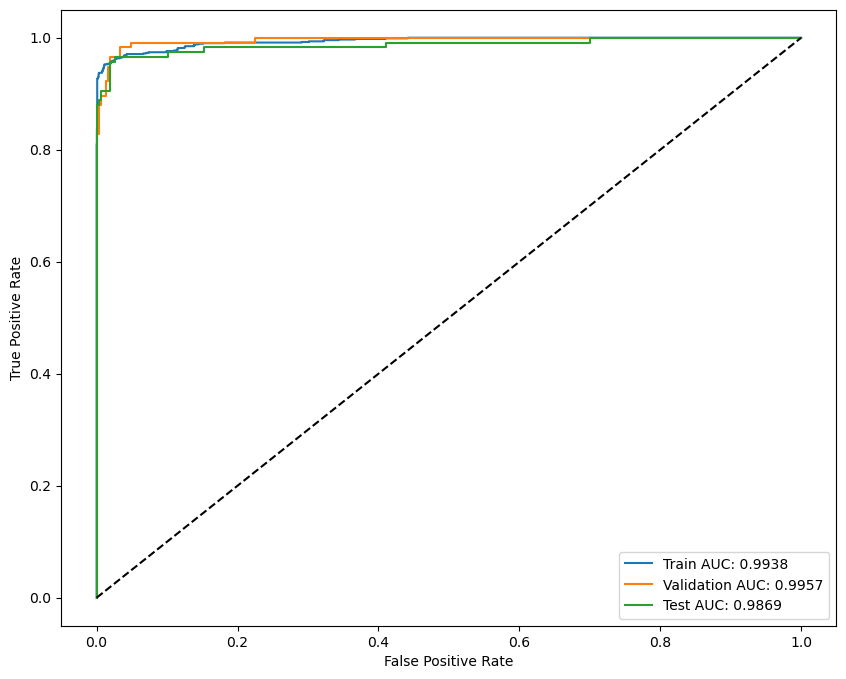

In [18]:
from sklearn.metrics import roc_curve, auc

probs_train = modelo.predict_proba(X_train)[:, 1]
probs_val = modelo.predict_proba(X_val)[:, 1]
probs_test = modelo.predict_proba(X_test)[:, 1]

fpr_train, tpr_train, _ = roc_curve(y_train, probs_train)
fpr_val, tpr_val, _ = roc_curve(y_val, probs_val)
fpr_test, tpr_test, _ = roc_curve(y_test, probs_test)

plt.figure(figsize=(10, 8))
plt.plot(fpr_train, tpr_train, label=f'Train AUC: {auc(fpr_train, tpr_train):.4f}')
plt.plot(fpr_val, tpr_val, label=f'Validation AUC: {auc(fpr_val, tpr_val):.4f}')
plt.plot(fpr_test, tpr_test, label=f'Test AUC: {auc(fpr_test, tpr_test):.4f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

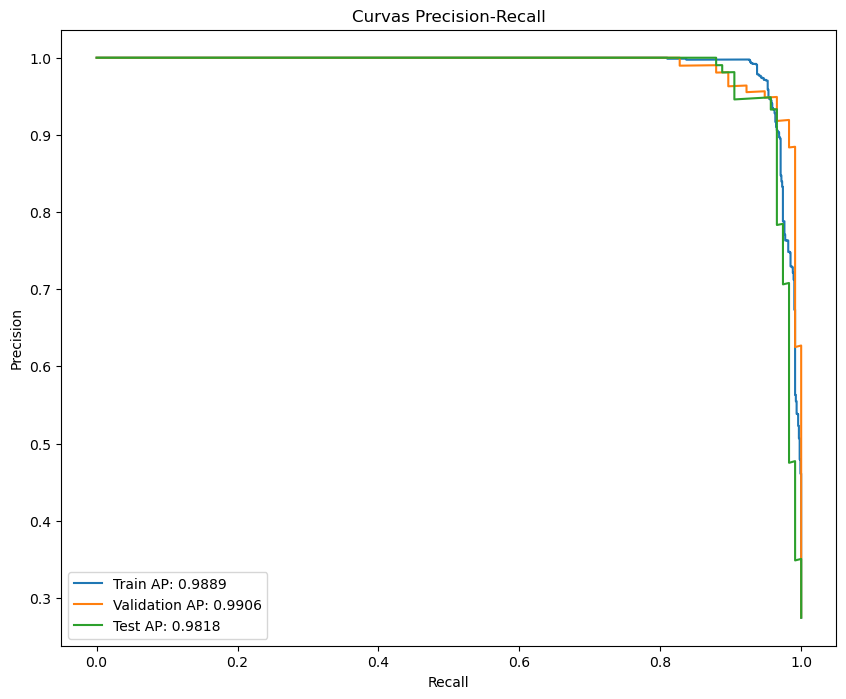

In [19]:
from sklearn.metrics import precision_recall_curve, average_precision_score

ap_train = average_precision_score(y_train, probs_train)
ap_val = average_precision_score(y_val, probs_val)
ap_test = average_precision_score(y_test, probs_test)

prec_train, rec_train, _ = precision_recall_curve(y_train, probs_train)
prec_val, rec_val, _ = precision_recall_curve(y_val, probs_val)
prec_test, rec_test, _ = precision_recall_curve(y_test, probs_test)


plt.figure(figsize=(10, 8))
plt.plot(rec_train, prec_train, label=f'Train AP: {ap_train:.4f}')
plt.plot(rec_val, prec_val, label=f'Validation AP: {ap_val:.4f}')
plt.plot(rec_test, prec_test, label=f'Test AP: {ap_test:.4f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curvas Precision-Recall')
plt.legend()
plt.show()